# Valuation da Gerdau S.A. (GGBR4) por FCD — versão 1

TCC de Ciências Econômicas (IE-UFRJ) · Guilherme Cabral Cavalcanti · orientador: Pedro Hemsley.

**Pergunta:** a janela usada para estimar as premissas (crescimento, margem, beta etc.) gera desvios
sistemáticos entre o valor justo e o preço, ligados à fase do ciclo do aço?

**O que este notebook faz**
1. Lê a planilha de dados (`Database Valuation Gerdau.xlsx`) do GitHub.
2. Em cada uma das 5 datas-base, usa só a informação disponível naquela data
   (última DFP entregue à CVM, preços até a véspera, pesquisa Focus mais recente).
3. Estima o beta por regressão CAPM e o prêmio de mercado a partir do Ibovespa e do CDI.
4. Calcula o valor justo por ação pelo fluxo de caixa livre da firma (FCFF) descontado pelo WACC.
5. Repete tudo com premissas estimadas em três janelas (3, 5 e 10 anos): são os cenários.
6. Compara o valor justo com o preço em cada data.

Método: Damodaran (FCFF/WACC). Nenhum número do site do Damodaran é usado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Link "raw" da planilha no GitHub (fonte única dos dados). Sem link, lê o arquivo local.
URL_DADOS = "https://raw.githubusercontent.com/gcabralcavalcanti/tcc-valuation-gerdau/main/4.%20Dados%20Gerdau/Database%20Valuation%20Gerdau.xlsx"
ARQUIVO_LOCAL = "../../4. Dados Gerdau/Database Valuation Gerdau.xlsx"

dados = pd.read_excel(URL_DADOS or ARQUIVO_LOCAL, sheet_name=None)
datas = dados["Datas-base"]
fund = dados["Fundamentos"].set_index("Ano")
precos = dados["Preços diários"].set_index("Data")
focus = dados["Expectativas Focus"]
datas

,Data-base,Último exercício publicado,Divulgação da DFP,GGBR4 na data (R$),Ações em circulação (mi),Valor de mercado (R$ mi),Dívida líquida (R$ mi)
0,2021-02-25,2020,2021-02-24,26.03,"1,701.16","44,281.23","9,857.00"
1,2022-02-24,2021,2022-02-23,24.28,"1,705.75","41,415.53","7,252.83"
2,2023-03-02,2022,2023-03-01,29.57,"1,663.56","49,191.48","7,172.39"
3,2024-02-21,2023,2024-02-20,21.84,"1,749.52","38,209.57","5,549.57"
4,2025-02-20,2024,2025-02-19,16.43,"2,041.29","33,538.45","5,359.64"


## 1. Ajustes nos fundamentos

**Itens extraordinários.** O EBIT da DRE inclui impairments (já separados na planilha) e ganhos que não se repetem.
Para estimar a margem operacional "normal", tiramos do EBIT os ganhos extraordinários identificados nos relatórios
anuais (20-F): créditos tributários de 2020 e 2023, o ganho com a Eletrobras em 2021 e os itens de 2024
(+808 e +101 de ganhos, −529 de perdas). Valores em R$ milhões.

In [2]:
EXTRAORDINARIOS = {2020: 1002, 2021: 1391, 2023: 700, 2024: 808 + 101 - 529}

f = fund.copy()
f["EBIT ajustado"] = f["EBIT sem impairment"] - pd.Series(EXTRAORDINARIOS).reindex(f.index).fillna(0)
f["Capital de giro"] = f["Contas a receber"] + f["Estoques"] - f["Fornecedores"]
f["Dívida total"] = f["Dívida bruta (sem arrendamentos)"] + f["Arrendamentos (IFRS 16)"]

# Razões anuais que viram premissas
r = pd.DataFrame(index=f.index)
r["Crescimento da receita"] = f["Receita líquida"].pct_change()
r["Margem EBIT"] = f["EBIT ajustado"] / f["Receita líquida"]
r["D&A / receita"] = f["Depreciação e amortização"] / f["Receita líquida"]
r["Capex / receita"] = f["Capex"] / f["Receita líquida"]
r["Capital de giro / receita"] = f["Capital de giro"] / f["Receita líquida"]
r["Alíquota efetiva"] = (-f["IR e CSLL"] / f["Lucro antes do IR"]).clip(0, 0.34)
r["Custo da dívida"] = -f["Despesas financeiras"] / f["Dívida total"].rolling(2, min_periods=1).mean()
r.style.format("{:.1%}")

,Crescimento da receita,Margem EBIT,D&A / receita,Capex / receita,Capital de giro / receita,Alíquota efetiva,Custo da dívida
Ano,,,,,,,
2009,nan%,7.2%,6.6%,5.2%,26.0%,2.6%,8.9%
2010,18.3%,10.5%,6.0%,4.4%,26.8%,17.0%,7.5%
2011,12.8%,8.1%,5.0%,5.9%,24.6%,10.8%,6.8%
2012,7.3%,6.2%,4.8%,8.6%,26.1%,4.1%,7.8%
2013,5.0%,6.9%,5.1%,6.9%,24.1%,0.0%,10.2%
2014,6.7%,7.6%,5.2%,5.7%,24.4%,0.0%,10.3%
2015,2.4%,4.1%,6.0%,5.6%,23.4%,24.6%,14.5%
2016,-13.6%,3.4%,6.7%,3.7%,20.8%,0.0%,8.7%
2017,-1.9%,6.0%,5.7%,2.5%,18.4%,0.0%,9.4%


## 2. Beta e prêmio de mercado

**Beta:** regressão do excesso de retorno semanal da GGBR4 sobre o excesso de retorno do Ibovespa
(ambos menos o CDI), só com preços até a véspera da data-base:

$$R_{GGBR4} - r_f = \alpha + \beta\,(R_{Ibov} - r_f) + \varepsilon$$

**Prêmio de mercado:** média anual do excesso de retorno do Ibovespa sobre o CDI, de 2009 até a data-base.
**Taxa livre de risco de longo prazo:** Selic esperada no Focus para o último ano da pesquisa (t+4), disponível na data.

In [3]:
# Retornos semanais (sexta a sexta). O Ibovespa já é índice de retorno total.
semanal = precos.resample("W-FRI").last()
cdi_sem = (1 + precos["CDI (% ao dia)"] / 100).resample("W-FRI").prod() - 1
ret = pd.DataFrame({
    "GGBR4": semanal["GGBR4 ajustada (R$)"].pct_change() - cdi_sem,
    "Ibovespa": semanal["Ibovespa (pontos)"].pct_change() - cdi_sem,
}).dropna()


def regressao_beta(data_base, anos):
    """Regressão CAPM com os `anos` de retornos semanais anteriores à data-base."""
    janela = ret[(ret.index < data_base) & (ret.index >= data_base - pd.DateOffset(years=anos))]
    return sm.OLS(janela["GGBR4"], sm.add_constant(janela["Ibovespa"])).fit()


def premio_mercado(data_base):
    """Excesso de retorno anual médio do Ibovespa sobre o CDI, de 2009 até a data-base."""
    p = precos[precos.index < data_base]
    anual = p.resample("YE").last()
    ret_ibov = anual["Ibovespa (pontos)"].pct_change()
    ret_cdi = (1 + p["CDI (% ao dia)"] / 100).resample("YE").prod() - 1
    return (ret_ibov - ret_cdi).dropna().mean()


# Exemplo: a regressão de 5 anos na última data-base, com a tabela completa
print(regressao_beta(datas["Data-base"].iloc[-1], 5).summary())

                            OLS Regression Results                            
Dep. Variable:                  GGBR4   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.399
Method:                 Least Squares   F-statistic:                     173.5
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           1.14e-30
Time:                        13:19:09   Log-Likelihood:                 443.04
No. Observations:                 261   AIC:                            -882.1
Df Residuals:                     259   BIC:                            -875.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0025      0.003      0.907      0.3

## 3. Modelo FCD

- **FCFF** = EBIT·(1 − t) + D&A − Capex − ΔCapital de giro
- **ke** = rf + β·(Rm − rf) · **kd** = despesa financeira / dívida média · **WACC** = E/(D+E)·ke + D/(D+E)·kd·(1 − t)
- 5 anos explícitos. O crescimento da receita começa no histórico da janela e converge linearmente
  até o crescimento da perpetuidade no ano 5.
- **Perpetuidade (Gordon):** g = (1 + IPCA esperado de longo prazo) × (1 + PIB esperado de longo prazo) − 1, do Focus.
  Usar o Focus resolve também a falta do PIB do último ano, que nas datas de fevereiro ainda não tinha saído.
- **Valor por ação** = (valor da firma − dívida líquida − arrendamentos − não controladores) / ações em circulação.
  Ações e preço são os da própria data, então as bonificações de 2023 e 2024 não distorcem a comparação.

In [4]:
ANOS_EXPLICITOS = 5


def premissas(ultimo_ano, anos):
    """Médias das razões na janela [ultimo_ano − anos + 1, ultimo_ano]."""
    jan = r.loc[ultimo_ano - anos + 1: ultimo_ano]
    p = jan.mean()
    receita = f["Receita líquida"]
    p["Crescimento da receita"] = (receita[ultimo_ano] / receita[ultimo_ano - anos]) ** (1 / anos) - 1
    return p


def valuation(linha, anos, ajustes=None):
    """Valor justo por ação numa data-base, com premissas estimadas numa janela de `anos` anos."""
    d, L = linha["Data-base"], int(linha["Último exercício publicado"])
    p = premissas(L, anos)
    for nome, valor in (ajustes or {}).items():   # troca uma premissa estimada por um valor fixo
        p[nome] = valor
    fo = focus.loc[focus["Data-base"] == d].iloc[0]

    # Custo de capital
    beta = regressao_beta(d, anos).params["Ibovespa"] if "Beta" not in p else p["Beta"]
    erp = premio_mercado(d) if "Prêmio de mercado" not in p else p["Prêmio de mercado"]
    rf = fo["Selic ano t+4 (%)"] / 100
    ke = rf + beta * erp
    E = linha["Valor de mercado (R$ mi)"]
    D = f.loc[L, "Dívida total"]
    t = p["Alíquota efetiva"]
    wacc = E / (D + E) * ke + D / (D + E) * p["Custo da dívida"] * (1 - t)
    g = (1 + fo["IPCA ano t+4 (%)"] / 100) * (1 + fo["PIB ano t+3 (%)"] / 100) - 1
    if "g perpetuidade" in p:
        g = p["g perpetuidade"]

    # Projeção
    receita, giro_ant, fcff = f.loc[L, "Receita líquida"], f.loc[L, "Capital de giro"], []
    for ano in range(1, ANOS_EXPLICITOS + 1):
        cresc = p["Crescimento da receita"] + (g - p["Crescimento da receita"]) * ano / ANOS_EXPLICITOS
        receita *= 1 + cresc
        giro = p["Capital de giro / receita"] * receita
        fcff.append(receita * (p["Margem EBIT"] * (1 - t) + p["D&A / receita"] - p["Capex / receita"])
                    - (giro - giro_ant))
        giro_ant = giro
    desconto = (1 + wacc) ** -np.arange(1, ANOS_EXPLICITOS + 1)
    terminal = fcff[-1] * (1 + g) / (wacc - g)
    firma = np.dot(fcff, desconto) + terminal * desconto[-1]

    equity = (firma - linha["Dívida líquida (R$ mi)"] - f.loc[L, "Arrendamentos (IFRS 16)"]
              - f.loc[L, "PL de não controladores"])
    return {"Data-base": d.date(), "Janela (anos)": anos, "Preço (R$)": linha["GGBR4 na data (R$)"],
            "Valor justo (R$)": equity / linha["Ações em circulação (mi)"],
            "Beta": beta, "Prêmio de mercado": erp, "rf": rf, "ke": ke, "WACC": wacc, "g": g,
            "Cresc. receita": p["Crescimento da receita"], "Margem EBIT": p["Margem EBIT"]}


JANELAS = [3, 5, 10]
res = pd.DataFrame([valuation(l, n) for n in JANELAS for _, l in datas.iterrows()])
res["Desvio (valor/preço − 1)"] = res["Valor justo (R$)"] / res["Preço (R$)"] - 1
res

,Data-base,Janela (anos),Preço (R$),Valor justo (R$),Beta,Prêmio de mercado,rf,ke,WACC,g,Cresc. receita,Margem EBIT,Desvio (valor/preço − 1)
0,2021-02-25,3,26.03,-388.91,1.23,-0.02,0.06,0.04,0.05,0.06,0.06,0.09,-15.94
1,2022-02-24,3,24.28,"-115,077.67",1.22,-0.02,0.07,0.04,0.05,0.05,0.19,0.15,"-4,740.61"
2,2023-03-02,3,29.57,"-1,449.35",1.15,-0.04,0.09,0.04,0.05,0.06,0.28,0.19,-50.01
3,2024-02-21,3,21.84,295.26,0.80,-0.03,0.09,0.06,0.08,0.06,0.16,0.20,12.52
4,2025-02-20,3,16.43,62.24,0.80,-0.03,0.10,0.07,0.09,0.06,-0.05,0.16,2.79
5,2021-02-25,5,26.03,-261.48,1.35,-0.02,0.06,0.03,0.05,0.06,0.00,0.07,-11.05
6,2022-02-24,5,24.28,"1,253.46",1.16,-0.02,0.07,0.04,0.06,0.05,0.16,0.12,50.63
7,2023-03-02,5,29.57,"-1,618.59",1.10,-0.04,0.09,0.04,0.06,0.06,0.17,0.15,-55.74
8,2024-02-21,5,21.84,405.58,1.10,-0.03,0.09,0.06,0.07,0.06,0.08,0.16,17.57
9,2025-02-20,5,16.43,195.17,1.14,-0.03,0.10,0.06,0.08,0.06,0.11,0.16,10.88


## 4. Preço × valor justo nas 5 datas

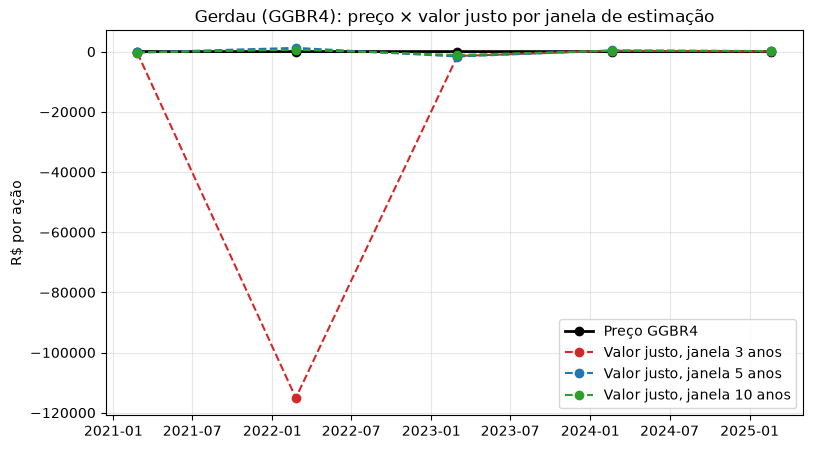

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pd.to_datetime(datas["Data-base"]), datas["GGBR4 na data (R$)"], "k-o", lw=2, label="Preço GGBR4")
for n, cor in zip(JANELAS, ["tab:red", "tab:blue", "tab:green"]):
    s = res[res["Janela (anos)"] == n]
    ax.plot(pd.to_datetime(s["Data-base"]), s["Valor justo (R$)"], "--o", color=cor, label=f"Valor justo, janela {n} anos")
ax.set_ylabel("R$ por ação")
ax.set_title("Gerdau (GGBR4): preço × valor justo por janela de estimação")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 5. Desvios por data e janela

Desvio positivo = o modelo diz que a ação está barata. A pergunta do TCC é se o sinal e o tamanho do desvio
seguem a fase do ciclo (2021–2022, pico do aço; 2023–2024, normalização).

In [6]:
res.pivot(index="Data-base", columns="Janela (anos)", values="Desvio (valor/preço − 1)").style.format("{:+.0%}")

Janela (anos),3,5,10
Data-base,,,
2021-02-25,-1594%,-1105%,-1183%
2022-02-24,-474061%,+5063%,+2540%
2023-03-02,-5001%,-5574%,-3848%
2024-02-21,+1252%,+1757%,+1385%
2025-02-20,+279%,+1088%,+1027%


## 6. Problema aberto: o prêmio de mercado histórico é negativo

De 2009 até cada data-base, o Ibovespa rendeu **menos** que o CDI (prêmio de −2% a −4% ao ano, tabela acima).
Com prêmio negativo, ke fica abaixo da taxa livre de risco, o WACC fica perto (ou abaixo) do crescimento da
perpetuidade e o valor justo explode ou fica negativo. Os resultados das seções 3–5 **não são utilizáveis** até
decidir como estimar o prêmio. A tabela abaixo é só um teste de sensibilidade com prêmios fixos, para mostrar que
o resto do modelo funciona; não é premissa do trabalho.

In [7]:
sens = pd.DataFrame([valuation(l, n, {"Prêmio de mercado": erp}) | {"Prêmio fixo": erp}
                     for erp in [0.05, 0.07] for n in JANELAS for _, l in datas.iterrows()])
sens.pivot_table(index="Data-base", columns=["Prêmio fixo", "Janela (anos)"], values="Valor justo (R$)").round(1)

Prêmio fixo     0.05              0.07            
Janela (anos)     3     5     10    3     5     10
Data-base                                         
2021-02-25     31.00 24.60 19.40 22.00 17.10 13.10
2022-02-24     88.60 80.60 46.30 68.20 63.10 35.90
2023-03-02    123.70 91.40 57.50 96.80 72.10 45.20
2024-02-21     87.60 55.10 42.30 73.40 44.40 33.90
2025-02-20     26.40 41.50 31.10 23.10 34.50 25.60

## Próximos passos (versão 2)
- Separar o crescimento histórico em efeito câmbio × crescimento em moeda local (receita no exterior convertida pela PTAX média).
- Calibração: achar, em cada data, a premissa que zera (valor justo − preço).
- Estratégia: comprar quando preço < valor justo; comparar com buy-and-hold e Ibovespa.